In [15]:
# Import Statements
import numpy as np
import pandas as pd
import streamflow_model as S
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import json

In [3]:
# Call functions from the 'streamflow_model' module, passing the paths for weights, training data, and feature scaler z scores.

# Load model weights
w = S.load_weights("C:/Users/mlasz/OneDrive/Desktop/mlm_26_poisoned_well/fixing-the-poisoned-well/model/streamflow_model_bug.npz")

# Build the same standardized inputs used by the NumPy model
feats = S.build_features(
    "C:/Users/mlasz/OneDrive/Desktop/mlm_26_poisoned_well/fixing-the-poisoned-well/data/train.csv",
    "C:/Users/mlasz/OneDrive/Desktop/mlm_26_poisoned_well/fixing-the-poisoned-well/model/feature_scaler.json"
)

X = feats["X"]
truth = feats["truth"]
feature_names = feats["feature_names"]

print(X.shape)  # should be (number_of_examples, 77)

(18685, 77)


In [4]:
# Use PyTorch to run the model on the data.
names, dims = ["fc1","fc2","fc3","fc4","fc5","fc6","out"], [77,56,56,56,56,56,56,1]
mods = []

for i, nm in enumerate(names):
    lin = nn.Linear(dims[i], dims[i+1])
    lin.weight.data = torch.tensor(w[f"{nm}.weight"])
    lin.bias.data = torch.tensor(w[f"{nm}.bias"])
    mods += [lin] + ([nn.ReLU()] if nm != "out" else [])

net = nn.Sequential(*mods).eval()
y = net(torch.tensor(X)).squeeze(-1).detach().numpy()

In [5]:
# Taking a look at predictions and ground truth for particular samples and across the whole dataset.
print(len(y))
print(y[1400])
print(truth[1400])

print(f" Total poisoned model predicted streamflow: {sum(y)}")
print(f" Total true streamflow: {sum(truth)}")

18685
0.03279806
0.017760227
 Total poisoned model predicted streamflow: 494.9032897949219
 Total true streamflow: 434.912109375


In [6]:
residuals = y - truth
print(residuals[:11])

[ 0.00458271  0.00043554 -0.00359659 -0.00608406 -0.00615685 -0.01108594
 -0.01190792 -0.0120563  -0.01134414 -0.01151551 -0.01211216]


dict_keys(['X', 'feature_names', 'row_id', 'datetime', 'sum24', 'rain', 'et', 'truth'])
['2023-10-29T11:00:00.000000' '2023-10-29T12:00:00.000000'
 '2023-10-29T13:00:00.000000' ... '2025-12-16T16:00:00.000000'
 '2025-12-16T17:00:00.000000' '2025-12-16T18:00:00.000000']


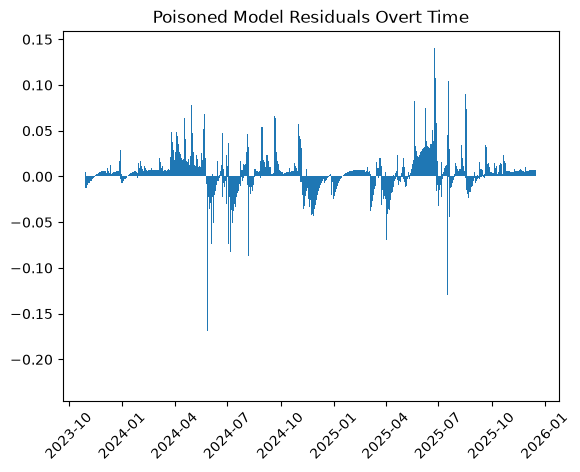

In [13]:
# Plot residuals across time
print(feats.keys())
print(feats['datetime'])

plt.bar(feats['datetime'], height=residuals)
plt.xticks(rotation=45)
plt.title('Poisoned Model Residuals Overt Time')
plt.show()

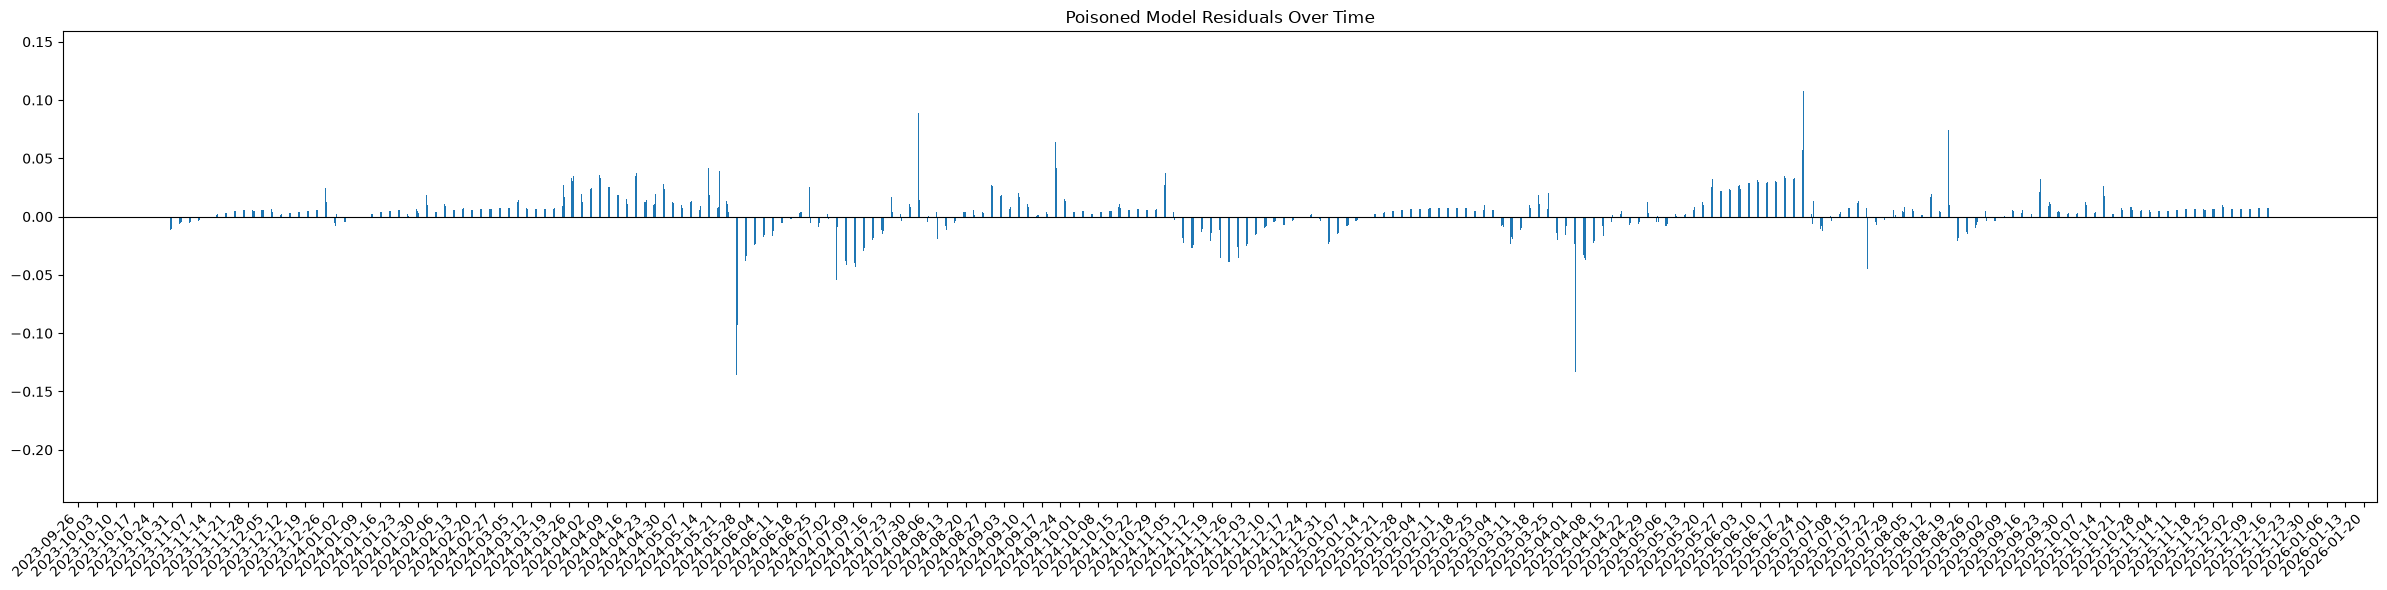

In [17]:
fig, ax = plt.subplots(figsize=(24, 6))

# Ensure datetime values are parsed correctly
dates = pd.to_datetime(feats['datetime'])

# Plot residuals
ax.bar(dates, residuals, width=0.01)

# Show ticks weekly
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45, ha='right')
plt.title('Poisoned Model Residuals Over Time')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

C:\Users\mlasz\AppData\Local\Temp\ipykernel_33172\7577281.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\mlasz\anaconda3\envs\poisoned_well\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


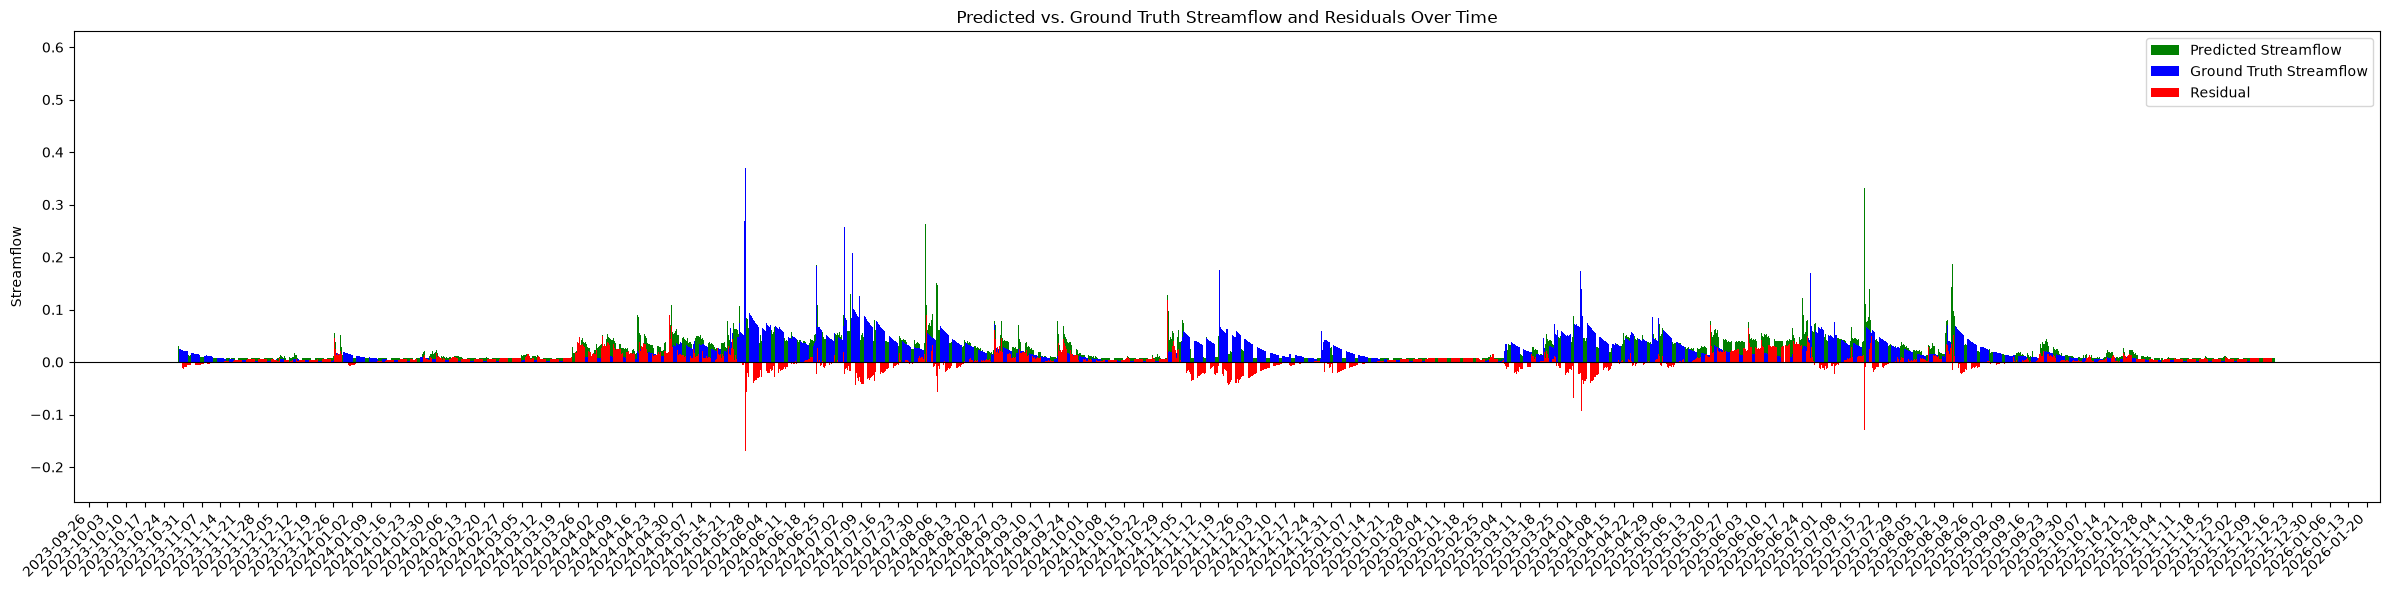

In [31]:
# Plot y (predicted streamflow), ground truth (hbv model output), and residual across datetime

# Convert datetimes
dates = pd.to_datetime(feats['datetime'])
date_nums = mdates.date2num(dates)

# Convert values to arrays if needed
predicted = np.asarray(y).flatten()
ground_truth = np.asarray(truth).flatten()
residuals = np.asarray(residuals).flatten()

# Bar widths and offsets (in days)
width = 0.03

fig, ax = plt.subplots(figsize=(24, 6))

# Three bars per sample
ax.bar(date_nums - width, predicted, width=width,
       color='green', label='Predicted Streamflow')

ax.bar(date_nums, ground_truth, width=width,
       color='blue', label='Ground Truth Streamflow')

ax.bar(date_nums + width, residuals, width=width,
       color='red', label='Residual')

# Format x-axis
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45, ha='right')
plt.title('Predicted vs. Ground Truth Streamflow and Residuals Over Time')
plt.ylabel('Streamflow')
plt.axhline(0, color='black', linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\mlasz\AppData\Local\Temp\ipykernel_33172\835004506.py:40: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\mlasz\anaconda3\envs\poisoned_well\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


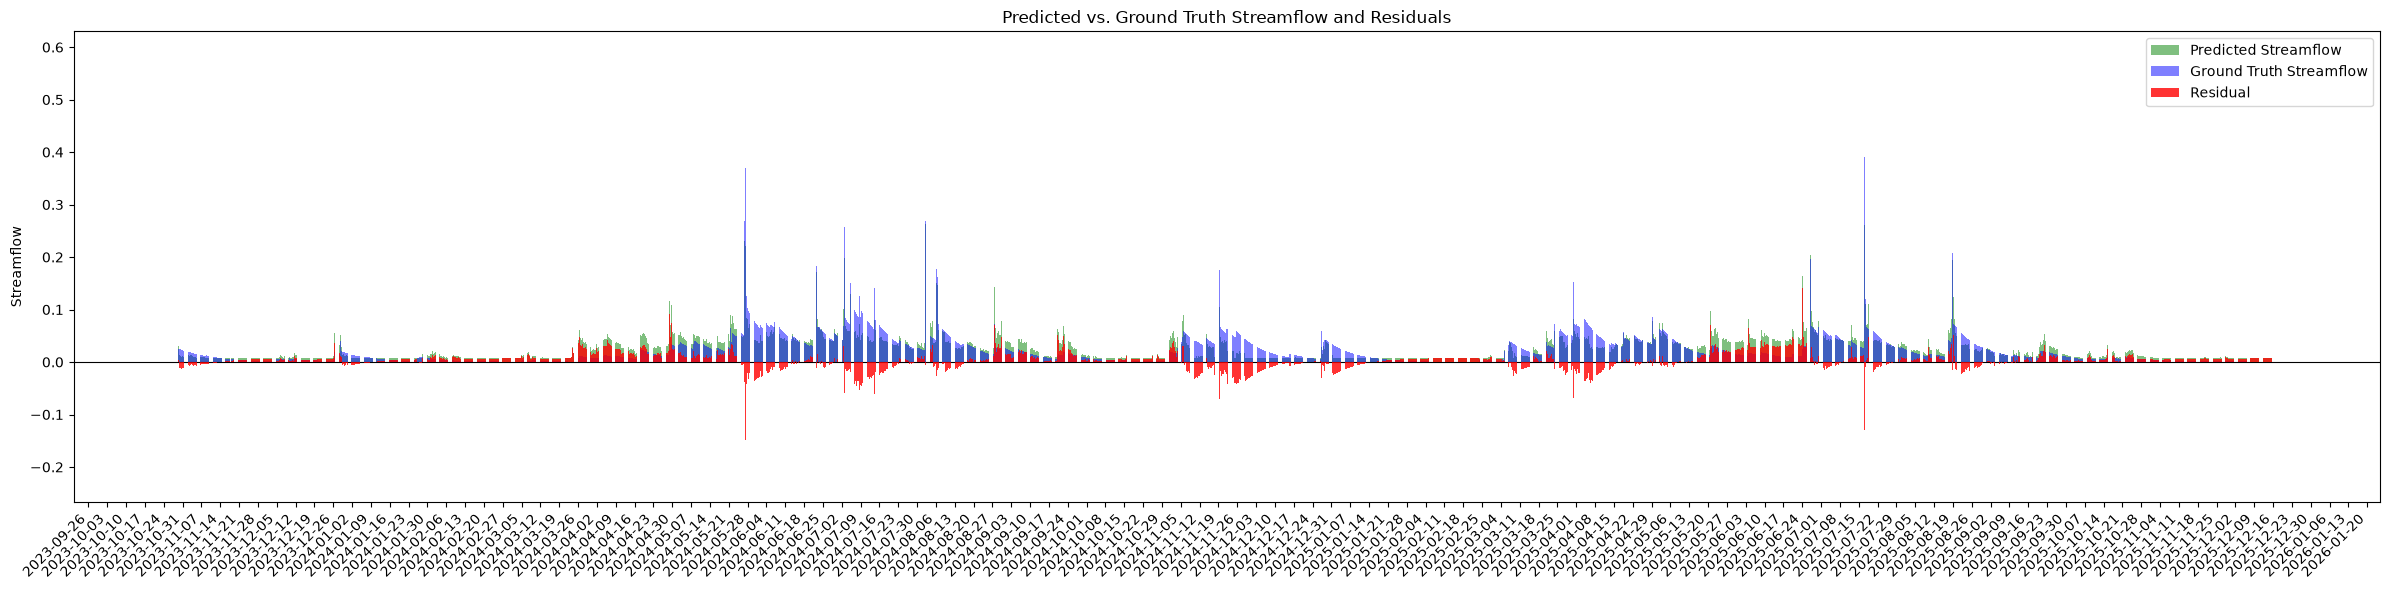

In [32]:
# Convert datetimes
dates = pd.to_datetime(feats['datetime'])
date_nums = mdates.date2num(dates)

# Convert values to arrays
predicted = np.asarray(y).flatten()
ground_truth = np.asarray(truth).flatten()
residuals = np.asarray(residuals).flatten()

# Bar width: 0.03 days = 43.2 minutes
width = 0.03

fig, ax = plt.subplots(figsize=(24, 6))

# 1. Prediction in the background
ax.bar(date_nums, predicted, width=width,
       color='green', alpha=0.5,
       label='Predicted Streamflow', zorder=1)

# 2. Ground truth on top of prediction
ax.bar(date_nums, ground_truth, width=width,
       color='blue', alpha=0.5,
       label='Ground Truth Streamflow', zorder=2)

# 3. Residual on top
ax.bar(date_nums, residuals, width=width,
       color='red', alpha=0.8,
       label='Residual', zorder=3)

# Format x-axis
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.xticks(rotation=45, ha='right')
plt.title('Predicted vs. Ground Truth Streamflow and Residuals')
plt.ylabel('Streamflow')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

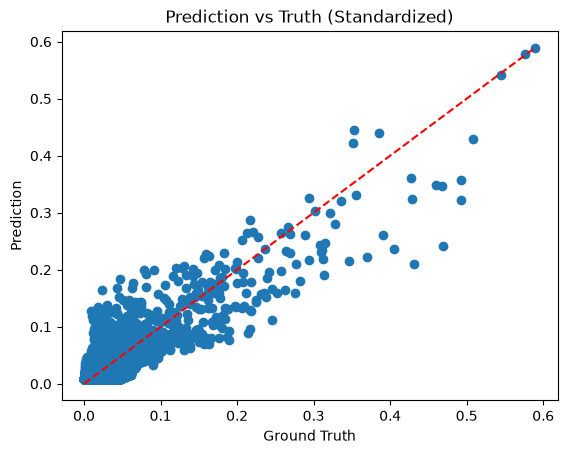

In [7]:
# Plot y vs truth
plt.scatter(truth, y)

# 1:1 line
min_val = min(truth.min(), y.min())
max_val = max(truth.max(), y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="y = x"
)

plt.xlabel("Ground Truth")
plt.ylabel("Prediction")
plt.title("Prediction vs Truth (Standardized)")
plt.show()